# *Análise exploratória de Monitoramento de Fauna*

### •Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
from datetime import time
#%pip install matplotlib
#%pip install plotly
#%pip install jinja2
import matplotlib.pyplot as plt
import plotly as py
from numpy import var
import random

### •Configuração para mostrar as linhas e colunas do arquivo

In [2]:
desired_width = 320
np.set_printoptions(linewidth=desired_width)
pd.set_option('display.width', desired_width)
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows', None)

### •Importação do Dataset

In [3]:
dt = pd.read_json("dataset_monitoramento_fauna.json")
display(dt.head().style.hide(axis='index'))#esconde o index já que existe a coluna de ID

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%


### •Informações gerais do Dataset

In [4]:
dt.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id_registro       5000 non-null   int64
 1   id_camera         5000 non-null   str  
 2   data_hora_inicio  5000 non-null   str  
 3   duracao_segundos  5000 non-null   int64
 4   especie           5000 non-null   str  
 5   grupo             5000 non-null   str  
 6   individuos        5000 non-null   int64
 7   temperatura_c     4753 non-null   str  
 8   umidade_pct       4825 non-null   str  
dtypes: int64(3), str(6)
memory usage: 351.7 KB


### •Mostrar primeiras e últimas linhas

In [5]:
display(pd.concat([dt.head(10), dt.iloc[-8:]]).style.hide(axis='index'))

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%
6,CAM08,2026-05-01 00:47:00,19,Sapo-cururu,Anfíbio,3,18.2 °C,90.9%
7,CAM12,2026-05-01 00:48:00,46,Quati,Mamífero,4,16.9 °C,95.5%
8,CAM05,2026-05-01 00:49:00,35,Perereca-verde,Anfíbio,2,14.6 °C,94.1%
9,CAM04,2026-05-01 00:49:00,46,Sapo-cururu,Anfíbio,3,20.6 °C,92.8%
10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%


### •Mostrar colunas com linhas em branco

In [6]:
colunas = dt.isnull().any()
print(colunas)

display(dt.columns[colunas])

id_registro         False
id_camera           False
data_hora_inicio    False
duracao_segundos    False
especie             False
grupo               False
individuos          False
temperatura_c        True
umidade_pct          True
dtype: bool


Index(['temperatura_c', 'umidade_pct'], dtype='str')

### •Qtd de linhas em branco

In [7]:
linhas = dt.columns[colunas]
dt[linhas].isnull().sum()


temperatura_c    247
umidade_pct      175
dtype: int64

### •Mostrar qtd de registros de cada espécie

In [8]:
dt[["id_registro","especie"]].groupby("especie").count().sort_values(by="id_registro",ascending=False)

,id_registro
especie,
Capivara,731
Sapo-cururu,564
Ema,551
Seriema,506
Lobo-guará,425
Tamanduá-bandeira,401
Perereca-verde,389
Quati,378
Rã-manteiga,317


### •Mostrar qtd de registros de cada Grupo

In [9]:
dt[["id_registro","grupo"]].groupby("grupo").count().sort_values(by="id_registro",ascending=False)

,id_registro
grupo,
Mamífero,2673
Anfíbio,1270
Ave,1057


### •Mostrar espécies únicas

In [10]:
dt.especie.unique()


<StringArray>
['Ema', 'Rã-manteiga', 'Tatu-canastra', 'Tamanduá-bandeira', 'Sapo-cururu', 'Quati', 'Perereca-verde', 'Capivara', 'Veado-campeiro', 'Lobo-guará', 'Seriema', 'Onça-pintada', 'Cervo-do-pantanal']
Length: 13, dtype: str

### •Mostrar qtd de registros por câmera

In [11]:
dt.id_camera.value_counts().reset_index()

,id_camera,count
0,CAM09,523
1,CAM12,504
2,CAM10,474
3,CAM02,471
4,CAM04,442
5,CAM08,418
6,CAM06,400
7,CAM01,394
8,CAM05,377
9,CAM07,364


### •Mostrar qtd de registros por câmera e epécie

In [12]:
resultado = (
    dt.value_counts(["id_camera", "especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["id_camera", "Qtd"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

resultado.head(30)

,id_camera,especie,Qtd
0,CAM01,Ema,80
1,CAM01,Seriema,76
2,CAM01,Lobo-guará,66
3,CAM01,Veado-campeiro,53
4,CAM01,Tamanduá-bandeira,35
5,CAM01,Tatu-canastra,32
6,CAM01,Sapo-cururu,14
7,CAM01,Quati,14
8,CAM01,Capivara,9
9,CAM01,Cervo-do-pantanal,7


### •Mostrar Qual epécie foi mais registrada

In [13]:
Qtd = (
    dt.value_counts(["especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["Qtd"],
        ascending=[False]
    ).reset_index(drop=True)
)

Qtd

,especie,Qtd
0,Capivara,731
1,Sapo-cururu,564
2,Ema,551
3,Seriema,506
4,Lobo-guará,425
5,Tamanduá-bandeira,401
6,Perereca-verde,389
7,Quati,378
8,Rã-manteiga,317
9,Veado-campeiro,292


## Desafio 1 - Animais solitários ou em grupo?

Durante o monitoramento, os pesquisadores querem entender como a **capivara** costuma ser registrada pelas câmeras.

**Pergunta:**

> **Qual é o número médio de indivíduos por registro de capivara? A maior parte dos registros envolve indivíduos isolados ou grupos?**

### •Mostrar registros da Capivara

In [14]:
capi = dt[(dt.especie=='Capivara')]
capi.head(10)


,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
9,10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%
22,23,CAM12,2026-05-01 03:06:00,37,Capivara,Mamífero,5,15.7 °C,98.6%
37,38,CAM09,2026-05-01 05:11:00,30,Capivara,Mamífero,11,18.3 °C,96.3%
45,46,CAM10,2026-05-01 06:04:00,4,Capivara,Mamífero,7,18.5 °C,88.0%
47,48,CAM12,2026-05-01 06:08:00,24,Capivara,Mamífero,3,17.7 °C,99.0%
49,50,CAM05,2026-05-01 06:31:00,53,Capivara,Mamífero,5,21.0 °C,91.7%
50,51,CAM09,2026-05-01 06:44:00,11,Capivara,Mamífero,6,18.2 °C,97.1%
55,56,CAM07,2026-05-01 07:13:00,16,Capivara,Mamífero,6,19.6 °C,84.1%
56,57,CAM07,2026-05-01 07:24:00,18,Capivara,Mamífero,6,17.5 °C,85.2%
62,63,CAM10,2026-05-01 08:01:00,6,Capivara,Mamífero,10,21.9 °C,94.9%


### *Número médio de indivíduos por registro:*

In [15]:
media = round(dt[(dt.especie=='Capivara')].individuos.mean(),2)
print("Média de indivíduos =", media)

Média de indivíduos = 5.95


### *Mostrar os registros de indivíduos solitários:*

In [16]:
capi_so_qtd = dt[(dt.especie=='Capivara') & 
                 (dt.individuos==1)
]['id_registro'].count()
capi_so = dt[(dt.especie=='Capivara') & 
             (dt.individuos==1)
][
    ['id_registro','individuos','data_hora_inicio']
]
print("Registros de Inivíduos Solitários =", capi_so_qtd)
display(capi_so)



Registros de Inivíduos Solitários = 6


,id_registro,individuos,data_hora_inicio
1973,1974,1,2026-05-12 18:15:00
2194,2195,1,2026-05-14 02:40:00
3972,3973,1,2026-05-24 17:04:00
4363,4364,1,2026-05-27 03:10:00
4556,4557,1,2026-05-28 07:20:00
4954,4955,1,2026-05-30 16:50:00


### *Mostrar os registros em grupo:*

In [17]:
capi_grp_qtd = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
    'id_registro'].count()

capi_grp = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
        ['id_registro','individuos','data_hora_inicio']
].sort_values(
    by='individuos', 
    ascending=False
).reset_index(drop=True)
print("Registros de Indivíduos em Grupos =", capi_grp_qtd)
display(capi_grp.head())


Registros de Indivíduos em Grupos = 725


,id_registro,individuos,data_hora_inicio
0,1068,14,2026-05-07 10:58:00
1,1648,14,2026-05-10 16:36:00
2,634,13,2026-05-04 19:31:00
3,936,13,2026-05-06 17:33:00
4,4943,13,2026-05-30 15:16:00


### Quantidade de Grupos encontrados

In [18]:
grupos = capi_grp['individuos'].value_counts().sort_index().reset_index()
grupos.columns = ['Individuos', 'Qtd_Registros']
display(grupos)

print("Total de grupos:", len(grupos))


,Individuos,Qtd_Registros
0,2,23
1,3,63
2,4,100
3,5,129
4,6,128
5,7,120
6,8,79
7,9,40
8,10,23
9,11,10


Total de grupos: 13


## Desafio 2 - Quando a fauna está mais ativa?

Depois de entender como os registros se distribuem entre as espécies, a equipe quer investigar **quando** os animais são mais frequentemente registrados.

**Pergunta:**

> **Em quais períodos do dia há mais registros de animais? Escolha três espécies e compare seus horários de maior ocorrência.**

### •Separar a coluna data_hora_inicio em Data e Hora

In [19]:
dt[['Data','Hora']] = dt['data_hora_inicio'].str.split(' ',n=1, expand=True)
dt['Hora'] = pd.to_datetime(dt['Hora'],format='%H:%M:%S').dt.time
dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00


### •Criação de uma coluna nova chamada Periodo, para facilitar a análise de acordo com o período do dia.

In [20]:
dt['Periodo'] = 'Manhã'

dt.loc[dt['Hora'].between(time(0, 0), time(5, 0)),'Periodo'] = 'Madrugada'
dt.loc[dt['Hora'].between(time(12, 0), time(18, 0)),'Periodo'] = 'Tarde'
dt.loc[dt['Hora'].between(time(19, 0), time(23, 0)),'Periodo'] = 'Noite'

dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada


### •Análise de Períodos do Dia

In [21]:
dt[["id_registro","Periodo"]].groupby("Periodo").count().sort_values(by="id_registro",ascending=False)

,id_registro
Periodo,
Manhã,2098
Tarde,1322
Madrugada,846
Noite,734


### •Gráfico simples de qtd de registros por período

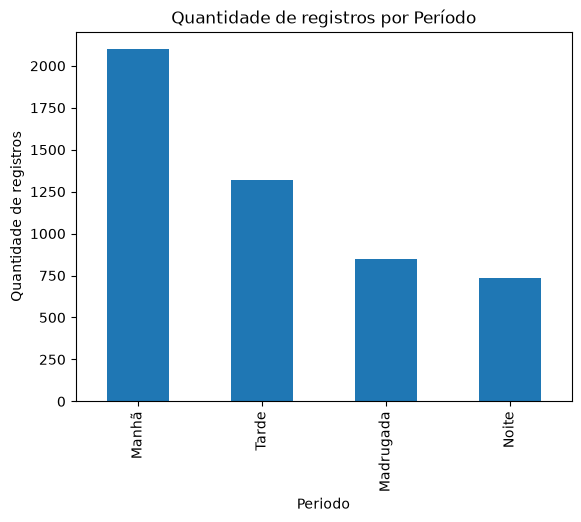

In [22]:
qtd_especies = dt.groupby('Periodo')['id_registro'].count().sort_values(ascending=False)
qtd_especies.plot(kind='bar')

plt.xlabel('Periodo')
plt.ylabel('Quantidade de registros')
plt.title('Quantidade de registros por Período')

plt.show()

### •Gráfico mais elaborado de qtd de registros por período

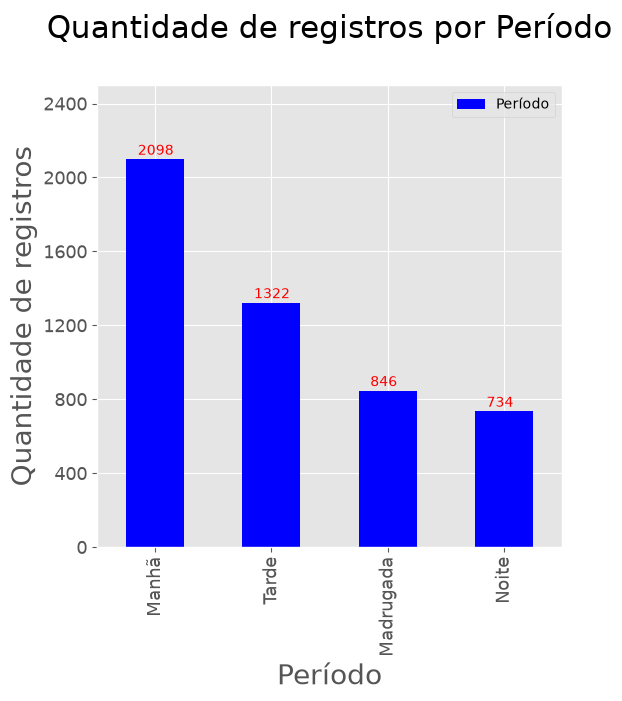

In [41]:
periodo = dt['Periodo'].value_counts()

grf = periodo.plot(
    kind='bar',
    rot=90, 
    figsize=(6,6),
    color='b',
    fontsize=13,
    label='Período'
    )
grf.set_title('Quantidade de registros por Período\n', fontsize=22, color='black')
grf.set_ylabel('Quantidade de registros', fontsize=20)
grf.set_xlabel('Período', fontsize=20)
grf.set_yticks([0,400,800,1200,1600,2000,2400])
grf.set_ylim((0,2500))

totals = []
total = sum(totals)
for i in grf.patches:
    grf.text(
        i.get_x() + 0.1, 
        i.get_height()+25,
        i.get_height(), 
        color='red'
    )
plt.style.use('ggplot')
plt.legend()
plt.show()

In [24]:
dt.especie.value_counts()#.plot(kind='bar', figsize=(10,6), color='g')

especie
Capivara             731
Sapo-cururu          564
Ema                  551
Seriema              506
Lobo-guará           425
Tamanduá-bandeira    401
Perereca-verde       389
Quati                378
Rã-manteiga          317
Veado-campeiro       292
Tatu-canastra        273
Cervo-do-pantanal    153
Onça-pintada          20
Name: count, dtype: int64

### •Análise de período por espécie

In [25]:
especies = dt[
    dt.especie.isin(['Perereca-verde', 'Ema', 'Onça-pintada'])
][
    ["especie","Periodo"]
].groupby(['especie', 'Periodo']).size().reset_index(name='Qtd').sort_values(
    by=['especie', 'Qtd'], ascending=False).style.hide(axis='index')
especies

#display(especies.style.hide(axis='index'))

especie,Periodo,Qtd
Perereca-verde,Noite,127
Perereca-verde,Manhã,120
Perereca-verde,Madrugada,111
Perereca-verde,Tarde,31
Onça-pintada,Manhã,7
Onça-pintada,Madrugada,6
Onça-pintada,Noite,6
Onça-pintada,Tarde,1
Ema,Manhã,243
Ema,Tarde,230


### •Gráfico comparativo de 3 espécies por períodos

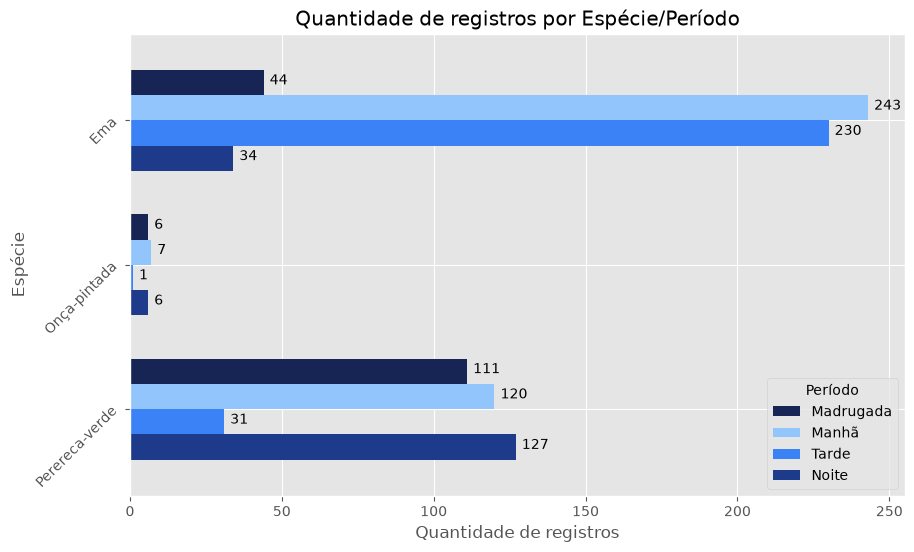

In [26]:
periodo_especie = dt[
    dt.especie.isin(['Perereca-verde', 'Ema', 'Onça-pintada'])
].groupby(
    ['Periodo', 'especie']
).size().reset_index(name='Qtd'
).pivot(
    index='especie',
    columns='Periodo',
    values='Qtd'
)
periodo_especie = periodo_especie[['Madrugada','Manhã', 'Tarde', 'Noite']]

ax = periodo_especie.plot(
    kind='barh',
    figsize=(10, 6),
    color=['#172554', '#93C5FD', '#3B82F6', '#1E3A8A'],
    width=0.7
)

ax.invert_yaxis()

totals = []
for i in ax.patches:
    totals.append(i.get_width())
total = sum(totals)
for i in ax.patches:
    ax.text(
        i.get_width()+2, 
        i.get_y()+0.1,
        i.get_width(),
        fontsize=10,
        color='black'
    )

plt.title('Quantidade de registros por Espécie/Período')
plt.xlabel('Quantidade de registros')
plt.ylabel('Espécie')
plt.yticks(rotation=45)
plt.legend(title='Período')
plt.show()

### •Gráfico comparativo de 3 espécies aleatórias por períodos

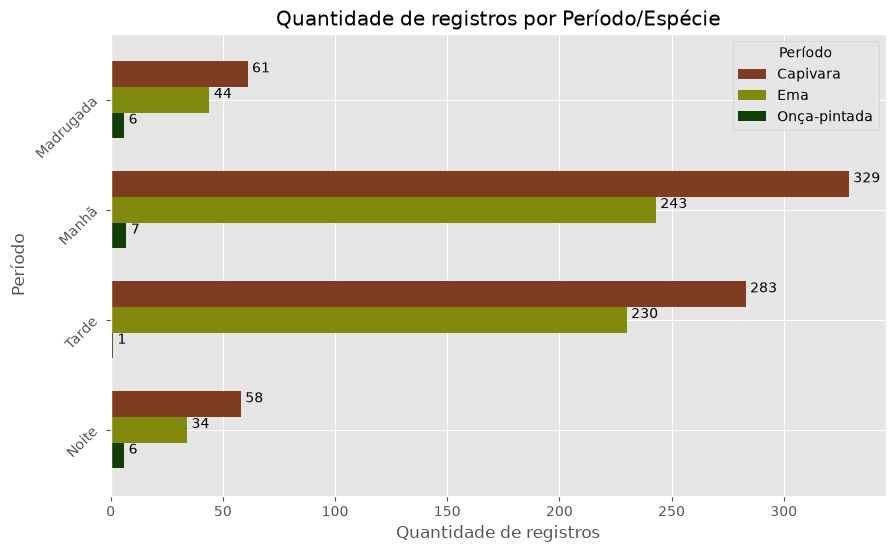

In [27]:
esp_aleat = random.sample(dt['especie'].unique().tolist(), 3)

periodo_especie = dt[
    dt.especie.isin(esp_aleat)
].groupby(
    ['Periodo', 'especie']
).size().reset_index(name='Qtd'
).pivot(
    index='Periodo',
    columns='especie',
    values='Qtd'
)
periodo_especie = periodo_especie.reindex(['Madrugada', 'Manhã', 'Tarde', 'Noite'])

ax = periodo_especie.plot(
    kind='barh',
    figsize=(10, 6),
    color=["#803C21", "#818A0D", "#123F05"],
    width=0.7
)

ax.invert_yaxis()

totals = []
for i in ax.patches:
    totals.append(i.get_width())
total = sum(totals)
for i in ax.patches:
    ax.text(
        i.get_width()+2, 
        i.get_y()+0.1,
        i.get_width(),
        fontsize=10,
        color='black'
    )

plt.title('Quantidade de registros por Período/Espécie')
plt.xlabel('Quantidade de registros')
plt.ylabel('Período')
plt.yticks(rotation=45)
plt.legend(title='Período')
plt.show()

## Desafio 3 - Vale a pena procurar anfíbios em períodos mais úmidos?

A equipe de campo está planejando uma rotina de monitoramento de anfíbios e quer saber se a umidade pode ajudar a definir os melhores momentos para realizar esse trabalho.

**Pergunta:**

> **Os anfíbios são registrados com maior frequência quando a umidade é mais alta? Compare a quantidade de registros em diferentes níveis de umidade e apresente sua conclusão.**

In [28]:
anfibios = dt[["umidade_pct","id_registro"]].groupby("umidade_pct").count().sort_values(by="id_registro",ascending=False)
anfibios.head(20)

,id_registro
umidade_pct,
99.0%,172
70.0%,30
64.0%,23
83.1%,19
79.8%,19
76.9%,19
74.3%,19
82.2%,19
68.5%,19


In [29]:
anfibios = dt[["id_registro","umidade_pct"]].groupby(["umidade_pct"]).count().sort_values(by="umidade_pct",ascending=False)
anfibios.head(30)

,id_registro
umidade_pct,
99.0%,172
98.9%,7
98.8%,6
98.7%,5
98.6%,4
98.5%,3
98.4%,6
98.3%,2
98.2%,7


In [30]:
anfibios = (
    dt[[
        "id_registro", 
        "umidade_pct", 
        "temperatura_c"]]
        .assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"
        ).round().astype("Int64")
    )
    .groupby(["umidade_pct", "temperatura_c"])
    .count()
    .sort_values(by="id_registro", ascending=False)
)

anfibios.head(30)

id_registro
umidade_pct temperatura_c             
99          17.6 °C                 10
            18.4 °C                 10
            17.5 °C                  8
            16.8 °C                  8
64          27.0 °C                  7
99          17.2 °C                  7
            16.7 °C                  7
92          18.7 °C                  6
99          17.4 °C                  6
81          21.2 °C                  6
99          17.8 °C                  6
91          18.6 °C                  6
82          23.0 °C                  6
66          27.3 °C                  6
65          26.9 °C                  6
66          25.8 °C                  6
69          25.4 °C                  6
67          27.5 °C                  6
86          19.7 °C                  6
68          27.1 °C                  6
78          24.9 °C                  6
84          19.4 °C                  6
99          16.5 °C                  6
            16.1 °C                  6
            15.7 °C                  6
58          26.4 °C                  5
73          24.5 °C                  5
77          24.2 °C                  5
89          18.4 °C                  5
66          26.8 °C                  5

In [31]:
dt["umidade_pct"].head(10)

0    81.5%
1    88.8%
2    96.3%
3    92.1%
4    82.6%
5    90.9%
6    95.5%
7    94.1%
8    92.8%
9    97.1%
Name: umidade_pct, dtype: str

In [32]:
anfibios = dt[[
    "id_registro",                
    "umidade_pct",                
    "temperatura_c"]].groupby([                   
        "umidade_pct",                    
        "temperatura_c"                    
        ]).count().sort_values(by="id_registro",ascending=False) 
anfibios.head(40)

id_registro
umidade_pct temperatura_c             
99.0%       18.4 °C                  9
            17.6 °C                  8
            16.7 °C                  7
            16.8 °C                  7
            17.2 °C                  7
            17.5 °C                  7
            16.1 °C                  5
            17.3 °C                  5
            15.7 °C                  5
            16.5 °C                  5
            17.8 °C                  5
            18.3 °C                  5
            15.8 °C                  4
            16.6 °C                  4
            17.4 °C                  4
            17.7 °C                  4
            18.2 °C                  4
            16.3 °C                  3
            16.4 °C                  3
68.5%       27.1 °C                  3
71.3%       28.0 °C                  3
70.0%       27.1 °C                  3
65.1%       27.9 °C                  3
99.0%       16.9 °C                  3
            17.0 °C                  3
66.4%       27.3 °C                  3
73.3%       24.3 °C                  3
77.9%       23.3 °C                  3
80.8%       22.0 °C                  3
83.4%       19.7 °C                  3
99.0%       20.1 °C                  3
89.0%       18.4 °C                  3
99.0%       15.0 °C                  3
            16.2 °C                  3
            18.8 °C                  3
            19.1 °C                  3
            19.4 °C                  3
72.8%       24.0 °C                  2
62.2%       26.2 °C                  2
65.9%       26.8 °C                  2

In [33]:
anfibios = (
    dt[[
        "id_registro", 
        "umidade_pct", 
        "temperatura_c"]]
        .assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"
        ).round().astype("Int64")
    )
    .groupby(["umidade_pct", "temperatura_c"])
    .count()
    .sort_values(by="umidade_pct", ascending=False)
)

anfibios.head(30)

id_registro
umidade_pct temperatura_c             
99          17.6 °C                 10
            19.0 °C                  3
            18.9 °C                  2
            18.8 °C                  3
            18.7 °C                  1
            18.5 °C                  2
            18.4 °C                 10
            18.3 °C                  5
            18.2 °C                  5
            18.1 °C                  1
            18.0 °C                  2
            17.9 °C                  3
            17.8 °C                  6
            21.5 °C                  1
            21.3 °C                  1
            20.8 °C                  1
            20.7 °C                  1
            20.3 °C                  1
            20.2 °C                  1
            20.1 °C                  4
            20.0 °C                  3
            19.9 °C                  1
            19.7 °C                  1
            19.6 °C                  1
            19.5 °C                  1
            19.4 °C                  3
            19.3 °C                  2
            19.1 °C                  3
            17.7 °C                  4
            15.9 °C                  1

In [34]:
qtd = (dt.assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"#transforma em NaN os valores que não puderem ser convertidos para numérico
        )
    )
    .assign(
        faixa_umidade=lambda x: pd.cut(
            x["umidade_pct"],
            bins=range(0, 101, 10),
            right=False
        )
    )
    ['faixa_umidade']
    .value_counts()
    .sort_index()
    .reset_index()
)

qtd.columns = ['faixa_umidade', 'qtd_registros']

qtd

,faixa_umidade,qtd_registros
0,"[0, 10)",0
1,"[10, 20)",0
2,"[20, 30)",0
3,"[30, 40)",0
4,"[40, 50)",32
5,"[50, 60)",436
6,"[60, 70)",1104
7,"[70, 80)",1227
8,"[80, 90)",1126
9,"[90, 100)",900


In [35]:
print(dt['umidade_pct'].dtype)
print(dt['umidade_pct'].min())
print(dt['umidade_pct'].max())

print(dt['Data'].dtype)
print(dt['Data'].min())
print(dt['Data'].max())

str
44.3%
99.0%
str
2026-05-01
2026-05-30


## Conclusão desafio 3

Inicialmente, nas consultas mais simples, os dados indicavam uma tendência de aumento no número de registros conforme a umidade aumentava. Ao dividir a umidade em faixas de 10%, foi possível observar que a maior quantidade de registros ocorreu entre 70% e 80% de umidade, com valores também elevados nas faixas de 60% a 70% e de 80% a 90%.

Para obter uma análise mais detalhada, reduzi o intervalo das faixas para 5%. Nesse cenário, as maiores ocorrências ficaram concentradas principalmente entre 65% e 80% de umidade, indicando que essa faixa apresenta as condições mais favoráveis para os registros de anfíbios.

**Dessa forma, com base nos dados analisados, concluo que a faixa de umidade entre 65% e 80% parece ser a mais favorável para encontrar anfíbios**.

In [36]:
qtd = (dt.assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"#transforma em NaN os valores que não puderem ser convertidos para numérico
        )
    )
    .assign(
        faixa_umidade=lambda x: pd.cut(
            x["umidade_pct"],
            bins=range(0, 101, 5),
            right=False
        )
    )
    ['faixa_umidade']
    .value_counts()
    .sort_index()
    .reset_index()
)

qtd.columns = ['faixa_umidade', 'qtd_registros']

qtd

,faixa_umidade,qtd_registros
0,"[0, 5)",0
1,"[5, 10)",0
2,"[10, 15)",0
3,"[15, 20)",0
4,"[20, 25)",0
5,"[25, 30)",0
6,"[30, 35)",0
7,"[35, 40)",0
8,"[40, 45)",2
9,"[45, 50)",30


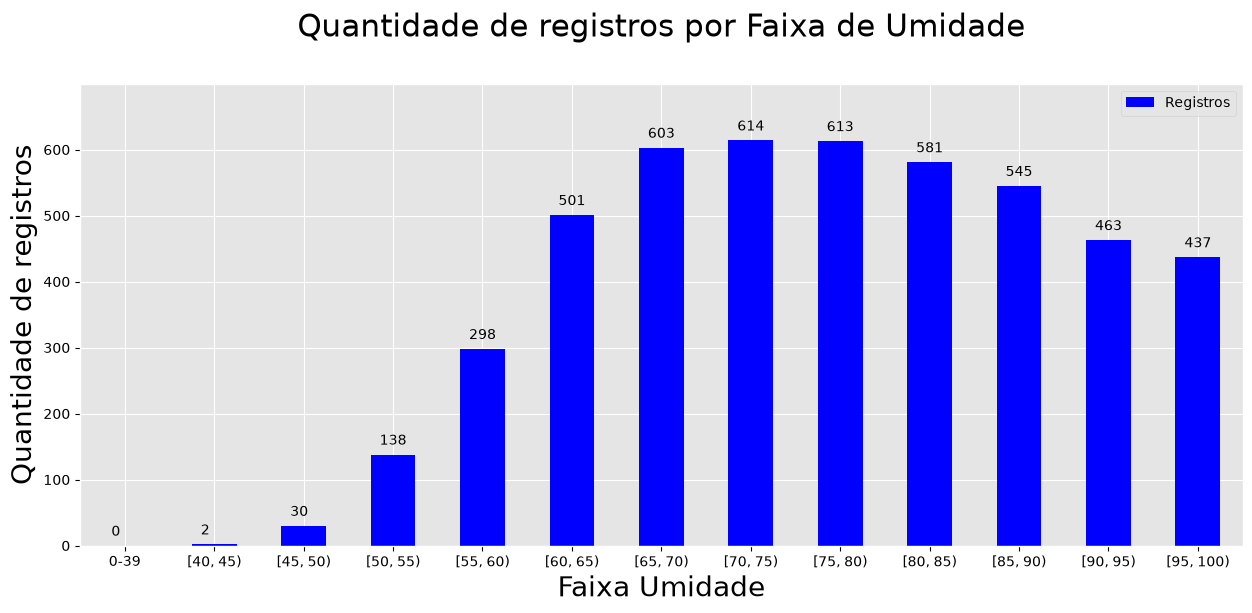

In [66]:
plt.style.use('ggplot')

qtd_grafico = qtd[qtd['qtd_registros'] > 0].copy()

qtd_grafico = pd.concat([
    pd.DataFrame({
        'faixa_umidade': ['0-39'],
        'qtd_registros': [0]
    }),
    qtd_grafico
], ignore_index=True) #agrupar as faixas com valor = 0

umid=qtd_grafico.set_index('faixa_umidade').plot(
    kind='bar',
    rot=0, 
    figsize=(15,6),
    color='b',
    fontsize=10,
    )


umid.legend(['Registros'])

umid.set_title('Quantidade de registros por Faixa de Umidade\n', fontsize=22, color='black')
umid.set_ylabel('Quantidade de registros', fontsize=20, color='black')
umid.set_xlabel('Faixa Umidade', fontsize=20, color='black')
umid.set_yticks(range(0,700,100))
umid.set_ylim((0,700))

umid.tick_params(axis='x', colors='black')
umid.tick_params(axis='y', colors='black')

totals = []
total = sum(totals)
for i in umid.patches:
    umid.text(
        i.get_x() + 0.1, 
        i.get_height()+15,
        i.get_height(), 
        color='black'
    )

plt.show()